# [Lab Session 3](fourier.ipynb)


In [4]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


In [5]:
cell_img = plt.imread('data/cells.png')
cell_img_res = resize(cell_img, (256, 256))
plt.imshow(cell_img_res, cmap= 'gray')
plt.colorbar()
plt.show()


<Figure size 640x480 with 2 Axes>

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [6]:
cell_ft = np.fft.fft2(cell_img_res)
cell_ft.dtype

dtype('complex128')

**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [7]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)


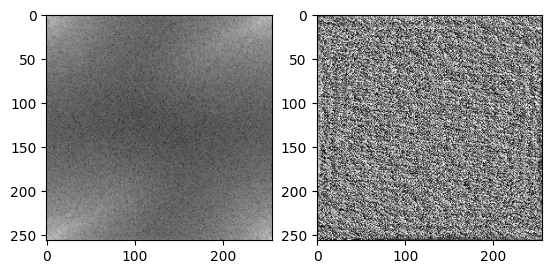

In [8]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


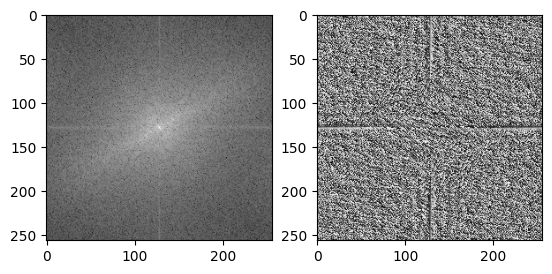

In [9]:
shift0 = np.fft.fftshift(cell_ft)

amplitude = np.abs(shift0)
phase = np.angle(shift0)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')


**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


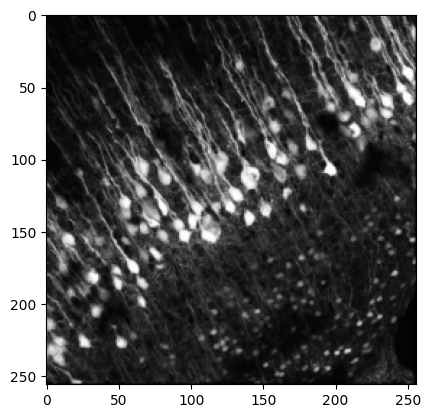

In [10]:
revshift = np.fft.ifftshift(shift0)
restored  = np.fft.ifft2(revshift).real

plt.figure()
plt.imshow(restored, 'gray')


---


**[Task 2 (a).]()** Load the brain MR image.


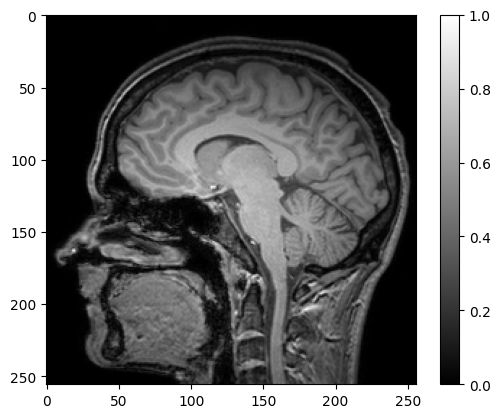

In [11]:
brain_img = plt.imread('data/brain_mri.png')
plt.imshow(brain_img, cmap='gray')
plt.colorbar()
plt.show()

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


In [12]:
brain_img_ft = np.fft.fft2(brain_img)
shift = np.fft.fftshift(brain_img_ft)

amplitudeb = np.abs(shift)
phaseb = np.angle(shift)




In [13]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


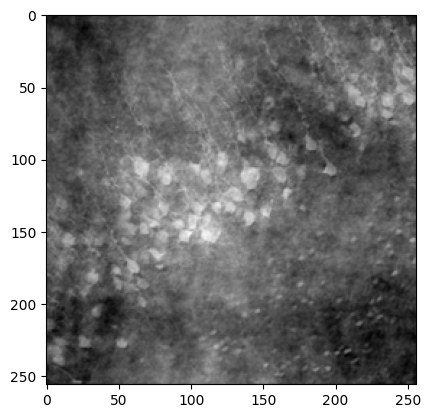

In [14]:
merge_shifted = to_complex_array(amplitudeb, phase)
merge_revshift = np.fft.ifftshift(merge_shifted)
merge_restored = np.fft.ifft2(merge_revshift).real

plt.figure()
plt.imshow(merge_restored, 'gray')




**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


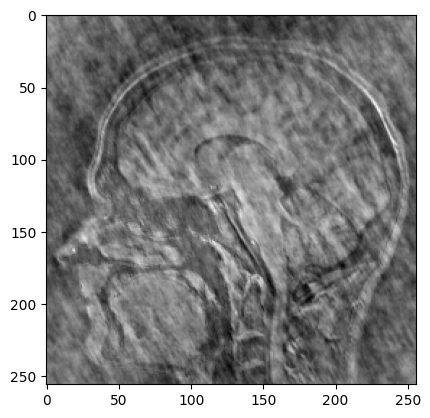

In [15]:
merge_shifted2 = to_complex_array(amplitude, phaseb)
merge_revshift2 = np.fft.ifftshift(merge_shifted2)
merge_restored2 = np.fft.ifft2(merge_revshift2).real

plt.figure()
plt.imshow(merge_restored2, 'gray')

---


**[Task 3 (a).]()** Create a lowpass filter mask.


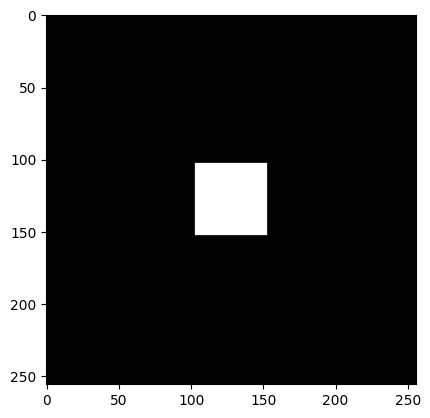

In [16]:
filter_window_size = 50

lp = np.zeros((256, 256))
lp[103:153, 103:153] = 1

plt.figure()
plt.imshow(lp, cmap= 'gray')
plt.show()


**[Task 3 (b).]()** Create a highpass filter maks.


In [17]:
hp = 1 - lp

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


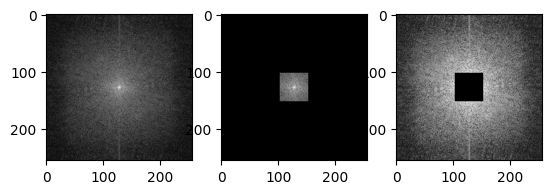

In [18]:
applp = lp * amplitudeb
apphp = hp * amplitudeb

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(np.log(amplitudeb + 1), 'gray')
plt.subplot(1, 3, 2)
plt.imshow(np.log(applp + 1), 'gray')
plt.subplot(1, 3, 3)
plt.imshow(np.log(apphp + 1), 'gray')

**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


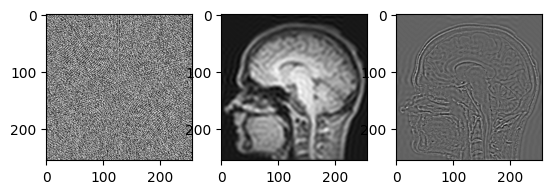

In [19]:
merge_filteredamplp = to_complex_array(applp, phaseb)
merge_filteredamphp = to_complex_array(apphp, phaseb)

merge_filteredamplp_revshift = np.fft.ifftshift(merge_filteredamplp)
merge_filteredamphp_revshift = np.fft.ifftshift(merge_filteredamphp)

merge_filteredamplp_restored = np.fft.ifft2(merge_filteredamplp_revshift).real
merge_filteredamphp_restored = np.fft.ifft2(merge_filteredamphp_revshift).real

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(phaseb, 'gray')
plt.subplot(1, 3, 2)
plt.imshow(merge_filteredamplp_restored, 'gray')
plt.subplot(1, 3, 3)
plt.imshow(merge_filteredamphp_restored, 'gray')

---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [20]:
def my_dft(img):
    dft = np.zeros(img.shape, dtype=complex)
    M, N = img.shape
    
    for u in range(M):
        for v in range(N):
            for x in range(M):
                for y in range(N):
                    dft[u, v] += img[x, y] * np.exp(-2j * np.pi * (u * x / M + v * y / N))
            dft[u, v] /= (M * N)
    return dft

**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [21]:
def my_idft(img):
    idft = np.zeros(img.shape, dtype=complex)
    M, N = img.shape
    
    for u in range(M):
        for v in range(N):
            for x in range(M):
                for y in range(N):
                  idft[u, v] += img[x, y] * np.exp(2j * np.pi * (u * x / M + v * y / N))
    return idft

Due to high computational costs, we need to resize the image.


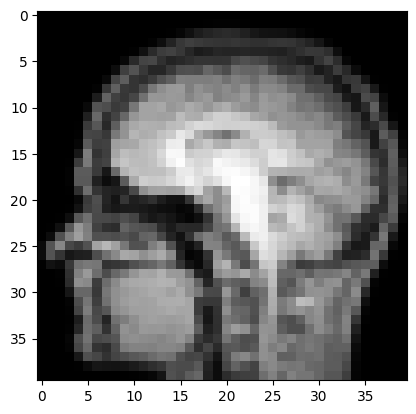

In [22]:
test_img = resize(brain_img, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


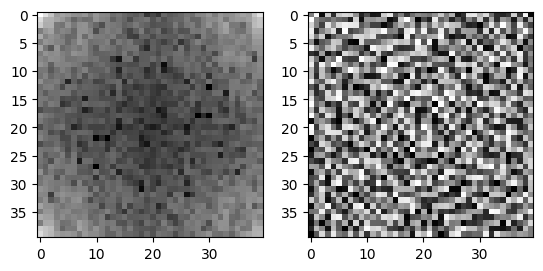

In [23]:
appdft = my_dft(test_img)

amplitude_test = np.abs(appdft)
phase_test = np.angle(appdft)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_test), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase_test, 'gray')



**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


<function matplotlib.pyplot.show(close=None, block=None)>

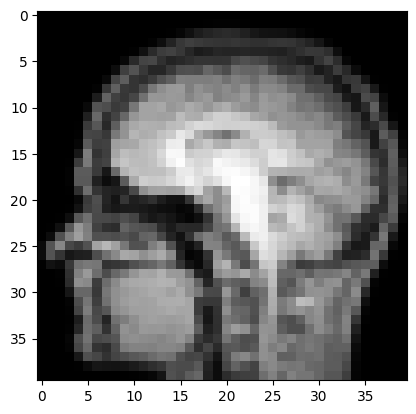

In [24]:
merge_testing = to_complex_array(amplitude_test, phase_test)
appidft = my_idft(merge_testing).real

plt.figure()
plt.imshow(appidft, 'gray')
plt.show

**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


In [25]:
dft_img = my_dft(test_img)
fft_brain = np.fft.fft2(test_img, norm='forward')

print(np.allclose(dft_img, fft_brain))



True


**[Task 4 (f).]()** Round the arrays and compare them again.


In [32]:
mean_diff = np.mean(np.abs(dft_img - fft_brain))

dft_round = np.round(dft_img, 5)
fft_round = np.round(fft_brain, 5)

print((dft_round == fft_round).all())

True


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)


In [33]:
%timeit my_dft(test_img)
%timeit np.fft.fft2(test_img, norm='forward')

5.74 s ± 50.8 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
38.8 μs ± 12.1 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
